# Windowed detrending: Python demonstration

Run all cells in order with the environment described in `ENVIRONMENT.md`.
The plugin is imported directly from source; no plugin installation is needed.
Start Jupyter from this `PythonPlugin` directory or the repository root.

Pipeline: pulse handling -> bad-trial/channel removal -> epoching -> windowed
detrending -> ICA -> feature extraction. This toy starts after epoching.


In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Locate the source relative to the notebook working directory.
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent / "src", parent / "PythonPlugin" / "src",
                       parent / "scripts" / "PythonPlugin" / "src"])
plugin_src = next((p for p in candidates
                   if (p / "windowed_detrend" / "__init__.py").is_file()), None)
if plugin_src is None:
    raise FileNotFoundError("Start Jupyter inside the windowedDetrend repository")
sys.path.insert(0, str(plugin_src))
from windowed_detrend import Config, detrend
print("Local plugin imported successfully")


Local plugin imported successfully


## A. Toy signal parameters

These values define the synthetic input, not the detrending fit.

In [2]:
toy = dict(
    background_amplitude=0.5, # Continuous synthetic background.
    background_frequency_hz=11, # Background frequency in Hz.
    fs_hz=10000,             # Sampling rate in Hz; keep enough samples per fit window.
    epoch_start_s=-0.100,    # First epoch sample, relative to TMS.
    epoch_end_s=0.250,       # Exclusive epoch end; last sample is one step earlier.
    onset_s=0.010,           # Synthetic artifact and oscillator onset.
    peak_s=0.015,            # Synthetic charging-to-discharging transition.
    tau_rise_s=0.003,        # Positive artifact charging time constant.
    tau_decay_s=0.200,       # Positive artifact discharging time constant.
    artifact_gain=-100.0,    # Signed artifact scale; positive values reverse polarity.
    neural_amplitude=5.0,   # Oscillator amplitude scale, arbitrary units.
    neural_frequency_hz=50.0, # Oscillator frequency in Hz.
    neural_damping_per_s=25.0, # Positive damping rate; envelope exp(-rate * time).
)


## B. Detrending parameters

All 22 core configuration fields are listed explicitly. The evaluation controls also live here.

In [3]:
detrend_parameters = dict(
    fill_mode="none",        # Demo: off. Use "gaussian" for experimental recordings.
    fill_seed=42,            # Reproducible within Python; change for another realization.
    fill_margin_s=0.005,     # Expand sampled rise by 5 ms each side; 0: only rise.
    mode="windowed",        # Our algorithm: separate rise and decay.
    onset_s=0.010,           # Fit start; choose after pulse-artifact handling.
    peak_s=None,             # Detect the peak in the user-chosen search window.
    peak_search_end_s=0.030, # Automatic search stops here, or at correction end.
    end_s=None,             # None uses last epoch sample; otherwise supply seconds.
    rise_model="lagrange",  # Alternatives: poly, singlerise (see options below).
    decay_model="poly",     # Alternatives: singledecay, doubledecay.
    rise_degree=3,          # Used only for poly; ignored for lagrange (degree N-1).
    decay_degree=3,         # Used for polynomial decay; e.g. 1, 3 or 5.
    pre_degree=None,        # None preserves pre-onset data; integer enables polynomial fit.
    constrain_rise=False,  # Required for lagrange; True anchors other rise fits to zero.
    constrain_decay=True,  # True anchors decay to observed signal at split; False frees it.
    fit_offset=False,      # Optional constant offset for exponential models only.
    tau_min_s=0.0005,       # Positive lower search bound for fitted exponential taus.
    tau_max_s=1.0,          # Upper search bound; must exceed tau_min_s.
    grid_size=21,           # Initial candidates per tau, integer >= 3.
    refinements=5,          # Default 5; integer >= 0. More levels improve tau resolution.
    channels=None,          # None: all channels; (0,) selects toy channel; () selects none.
    global_model="biexp",   # Inactive in windowed mode; external-comparator setting only.
)

# Evaluation and display are independent of fitting parameters.
evaluation_start_s = toy["onset_s"]
evaluation_end_s = None       # None: last epoch sample; MSE interval for the polynomial fit.
plot_limits_ms = (-20, 250)   # Display only; does not change fitting or MSE.


## Parameter options and interpretation

Edit only the parameter cells above, then **Restart Kernel and Run All Cells**.
Toy parameters generate the input. Detrending parameters control its analysis;
changing the toy does not automatically change the fit onset or supplied split.
The toy uses one epoch and one channel, without noise or pulse artifact.

| Choice | Available alternatives and effect |
|---|---|
| `peak_s` | `0.015` is the known toy split; `None` detects maximum absolute input amplitude. Inspect automatic peaks. |
| `rise_model` | `lagrange`: interpolation of all rise nodes; `poly`: least-squares polynomial; `singlerise`: exponential charging. |
| `decay_model` | `poly`: polynomial; `singledecay`: one exponential; `doubledecay`: sum of two exponentials. |
| Polynomial degrees | Nonnegative integers; 1 is linear, 3 cubic, 5 quintic. More flexibility can absorb neural activity. |
| `constrain_rise` | Keep False with Lagrange. True imposes zero at rise onset for compatible other models. |
| `constrain_decay` | True anchors to the observed split amplitude, which may contain neural activity; False fits freely. |
| `pre_degree` | None leaves pre-onset samples untouched; 0 removes a fitted constant, 1 a linear trend. |
| `fit_offset` | False omits an exponential offset; True estimates one. Inactive for polynomial/Lagrange fits. |
| Tau bounds and search | Used only by exponential fits. These are fitted-parameter bounds, not the toy's generating taus. Larger grids/refinements increase computation. |
| `channels` | None selects all; use a tuple of zero-based indices for selected channels. The toy has only index 0. |
| `mode`, `global_model` | Keep mode='windowed' for our algorithm. The core also exposes mode='global' for external comparison only, with global_model='biexp'; it is not a windowed-processing step. |

Additional basis functions in the core are `alpha` (alpha-shaped transient)
and `biexp` (multiplicative rise/decay bi-exponential). These are advanced
options, not recommended presets for individual rise/decay windows. Lagrange
requires no anchor; zero-at-origin models cannot satisfy an arbitrary nonzero
anchor without an appropriate offset. Not all model/constraint combinations
are valid.

**Presets:** default `lagrange` / `poly` with degree 3 and unconstrained rise;
polynomial alternative `poly` / `poly` with degrees 3/3 or 3/5 and optional
zero-onset rise constraint; exponential alternative `singlerise` /
`singledecay` with constrained rise and decay.

All times are seconds except `plot_limits_ms`. Artifact constants must be
positive and the synthetic peak must follow onset. A fit peak must lie
strictly inside its correction interval. Lagrange needs at least two rise
samples; polynomial fits need at least max(4, degree+2) samples, and
exponential fits at least four. Do not upsample to create independent data.

**Lagrange subtraction zeroes all rise samples, including neural activity.**
The Lagrange degree is N-1, regardless of `rise_degree`. The demo detects the split within the search window configured above.

### Relationship to the paper scripts

This is a standalone adaptation, not an exact numerical reproduction. The
synthetic construction and rise/decay separation are comparable. Exponential
fits use log-tau grid search with refinement instead of the original SciPy
curve_fit. Lagrange interpolation uses its exact values at the input nodes,
instead of high-degree monomial fitting. Historical figure configurations
include cubic rise / quintic decay; automatic optimized order selection is
not implemented here. Agreement between the Python and MATLAB plugins does
not establish full equivalence to the paper scripts. See ../PAPER_ALIGNMENT.md.



## 1. Generate the toy signal

In [4]:
assert toy["fs_hz"] > 0 and toy["epoch_end_s"] > toy["epoch_start_s"]
assert toy["epoch_start_s"] <= toy["onset_s"] < toy["peak_s"] < toy["epoch_end_s"]
assert toy["tau_rise_s"] > 0 and toy["tau_decay_s"] > 0
sample_start = int(round(toy["epoch_start_s"] * toy["fs_hz"]))
sample_stop = int(round(toy["epoch_end_s"] * toy["fs_hz"]))
times = np.arange(sample_start, sample_stop) / toy["fs_hz"]
u = np.maximum(times - toy["onset_s"], 0)
neural = toy["neural_amplitude"] * np.exp(-toy["neural_damping_per_s"] * u) * np.sin(2*np.pi*toy["neural_frequency_hz"]*u)
neural += toy["background_amplitude"] * np.sin(2*np.pi*toy["background_frequency_hz"]*times)
artifact = toy["artifact_gain"] * (1-np.exp(-u/toy["tau_rise_s"]))
decay = times >= toy["peak_s"]
artifact[decay] = toy["artifact_gain"] * (1-np.exp(-(toy["peak_s"]-toy["onset_s"])/toy["tau_rise_s"])) * np.exp(-(times[decay]-toy["peak_s"])/toy["tau_decay_s"])
data = (neural + artifact)[None, None, :]
print("Array shape (epochs, channels, samples):", data.shape)


Array shape (epochs, channels, samples): (1, 1, 3500)


## 2. Apply the detrending function

Configuration is taken from section B without overriding it below.

In [5]:
cfg = Config(**detrend_parameters)
corrected, trend, diagnostics = detrend(data, times, cfg)
detected_peak_s = diagnostics["fits"][0]["peak_s"]
print("Detected/supplied split (ms):",1000*detected_peak_s,"toy split (ms):",1000*toy["peak_s"])
assert corrected.shape == data.shape
if cfg.pre_degree is None:
    outside = times < cfg.onset_s
    for fit in diagnostics["fits"]:
        protected = outside.copy()
        if "fill" in fit:
            fill = fit["fill"]
            protected[fill["target_first"]:fill["target_last"]+1] = False
        np.testing.assert_array_equal(corrected[fit["epoch"],fit["channel"],protected],
                                      data[fit["epoch"],fit["channel"],protected])
if cfg.mode == "windowed" and cfg.rise_model == "lagrange":
    for fit in diagnostics["fits"]:
        rise = (times >= cfg.onset_s) & (times < fit["peak_s"])
        before_fill = data - trend
        np.testing.assert_allclose(before_fill[fit["epoch"],fit["channel"],rise],0,atol=1e-12)
print("Output dimensions and applicable preservation checks passed")


Detected/supplied split (ms): 23.599999999999998 toy split (ms): 15.0
Output dimensions and applicable preservation checks passed


## 3. Evaluate recovery

MSE compares against the known clean oscillator plus background, not the contaminated input. The decay-only score uses the synthetic artifact peak, independently of the fitted split.

In [6]:
evaluation_end = times[-1] if evaluation_end_s is None else evaluation_end_s
mask = (times >= evaluation_start_s) & (times <= evaluation_end)
decay_mask = mask & (times >= toy["peak_s"])
assert np.any(mask) and np.any(decay_mask), "Evaluation windows must contain samples"
for label, selected in [("Evaluation interval", mask), ("Toy decay interval", decay_mask)]:
    score = np.mean((corrected[0, 0, selected] - neural[selected]) ** 2)
    print(f"{label}: recovery MSE = {score:.6f} a.u.^2")


Evaluation interval: recovery MSE = 1.013752 a.u.^2
Toy decay interval: recovery MSE = 0.764639 a.u.^2


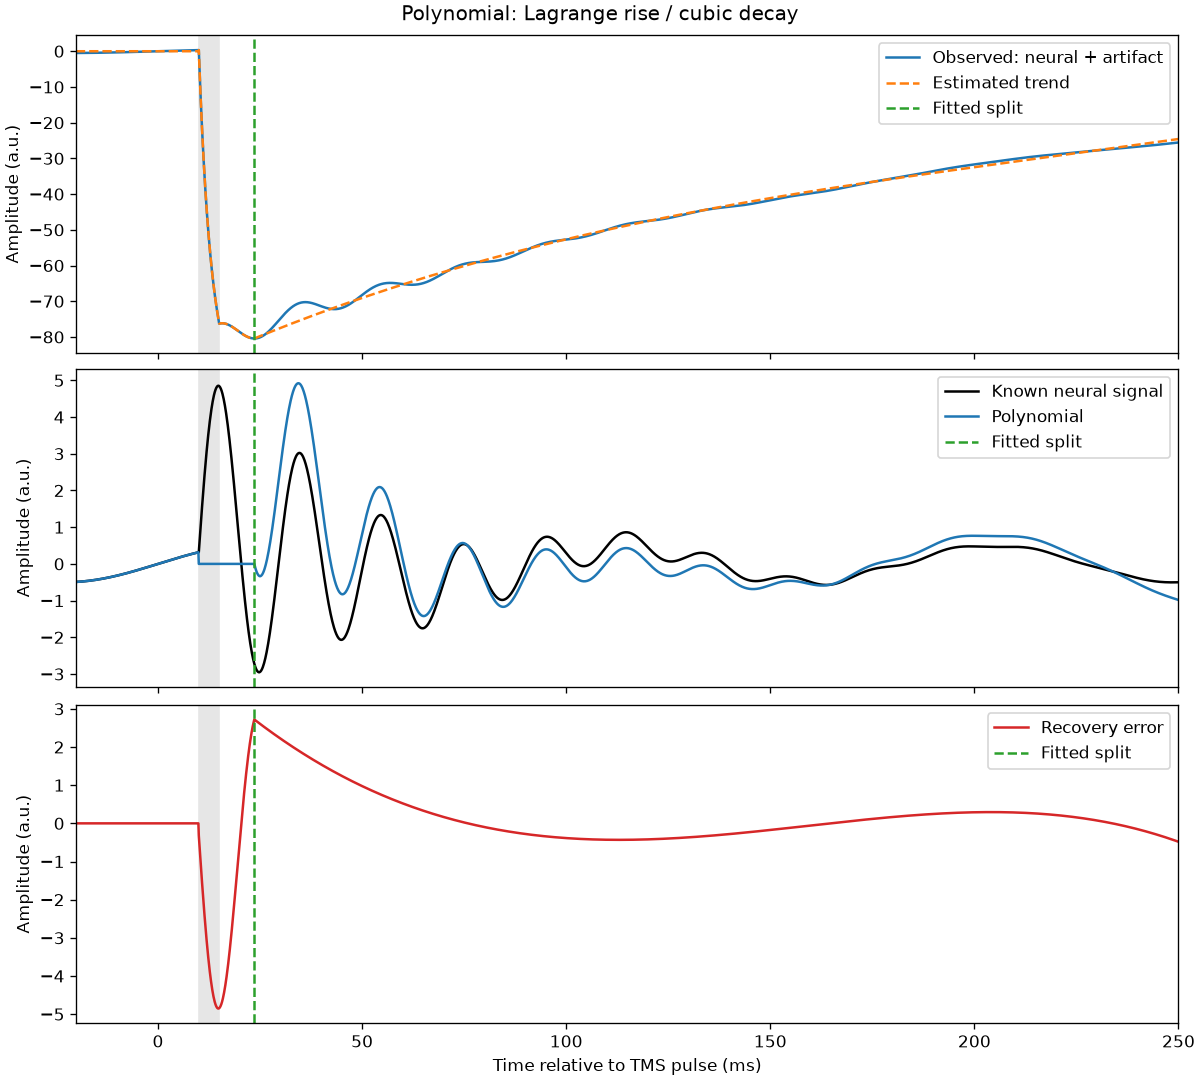

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True,
                         layout="constrained")
axes[0].plot(times * 1000, data[0, 0], label="Observed: neural + artifact")
axes[0].plot(times * 1000, trend[0, 0], "--", label="Estimated trend")
axes[1].plot(times * 1000, neural, "k", label="Known neural signal")
axes[1].plot(times * 1000, corrected[0, 0], label="Polynomial")
axes[2].plot(times * 1000, corrected[0, 0] - neural, color="tab:red",
             label="Recovery error")
for ax in axes:
    ax.axvspan(toy["onset_s"] * 1000, toy["peak_s"] * 1000, color="0.9")
    ax.axvline(detected_peak_s*1000, linestyle="--", color="tab:green", label="Fitted split")
    ax.set_ylabel("Amplitude (a.u.)")
    ax.legend(loc="best")
axes[-1].set_xlabel("Time relative to TMS pulse (ms)")
axes[-1].set_xlim(*plot_limits_ms)
fig.suptitle("Polynomial: Lagrange rise / cubic decay")
plt.show()


## 4. Use your own data

Replace the toy arrays with your preprocessed epochs x channels x samples
array and times in seconds. Edit the configuration in section B, then use
`detrend(data, times, cfg)` or `detrend_mne(epochs, cfg)` for an existing MNE
dataset. Inspect the output before fitting subsequent ICA. See
`../POST_EPOCHING_GUIDE.md` for the full Python and MATLAB workflow.
